In [3]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

## Clean Data

In [4]:
input_data = Path("Zomato Restaurant Dataset.csv")

# Load the dataset
df_raw = pd.read_csv(input_data, encoding="utf-8-sig")
df = df_raw.copy()
print("Successfully loaded the dataset with shape:", df.shape)

Successfully loaded the dataset with shape: (9551, 21)


In [5]:
# Normalize the column names
df.columns = df.columns.str.strip()
print(df.columns)

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='str')


In [6]:
initial_rows = len(df)

# Data-quality flags
df["Missing Cuisine"] = df["Cuisines"].isna()
df["Is Unrated"] = df["Aggregate rating"].eq(0)
df["Has Zero Cost"] = df["Average Cost for two"].eq(0)
df["Has Zero Coordinates"] = df[["Latitude", "Longitude"]].eq(0).any(axis=1)

assert len(df) == initial_rows, "Row count changed after adding flags"
assert df["Restaurant ID"].is_unique, "Restaurant ID is not unique"
assert df["Aggregate rating"].between(0, 5).all(), "Aggregate rating is out of bounds"

# Printing summary statistics
print("Initial rows:", initial_rows)
print("Final rows:", len(df))
print("Missing Cuisine:", df["Missing Cuisine"].sum())
print("Unrated restaurants:", df["Is Unrated"].sum())
print("Restaurants with zero cost:", df["Has Zero Cost"].sum())
print("Restaurants with zero coordinates:", df["Has Zero Coordinates"].sum())

Initial rows: 9551
Final rows: 9551
Missing Cuisine: 9
Unrated restaurants: 2148
Restaurants with zero cost: 18
Restaurants with zero coordinates: 499


# Restaurant Geographical Distribution

## Country Distribution

In [7]:
country_summary = (
    df.groupby(["Country Code", "Currency"]).size().reset_index(name="Restaurant Count").sort_values(by="Restaurant Count", ascending=False)
)
country_summary["Share (%)"] = (
    round(country_summary["Restaurant Count"] / country_summary["Restaurant Count"].sum() * 100, 2)
)
print(country_summary)

    Country Code                Currency  Restaurant Count  Share (%)
0              1      Indian Rupees(Rs.)              8652      90.59
14           216               Dollar($)               434       4.54
13           215              Pounds(��)                80       0.84
12           214      Emirati Diram(AED)                60       0.63
9            189                 Rand(R)                60       0.63
2             30      Brazilian Real(R$)                60       0.63
5            148           NewZealand($)                40       0.42
11           208        Turkish Lira(TL)                34       0.36
1             14               Dollar($)                24       0.25
6            162        Botswana Pula(P)                22       0.23
4             94  Indonesian Rupiah(IDR)                21       0.22
7            166         Qatari Rial(QR)                20       0.21
10           191   Sri Lankan Rupee(LKR)                20       0.21
8            184    

## Cities Distribution

In [8]:
city_summary = (
    df.groupby(["Country Code", "City"]).size().reset_index(name="Restaurant Count").sort_values(by="Restaurant Count", ascending=False)
)
city_summary["Share (%)"] = (
    round(city_summary["Restaurant Count"] / city_summary["Restaurant Count"].sum() * 100, 2)
)
city_summary.head(10)

,Country Code,City,Restaurant Count,Share (%)
31,1,New Delhi,5473,57.30
15,1,Gurgaon,1118,11.71
32,1,Noida,1080,11.31
12,1,Faridabad,251,2.63
13,1,Ghaziabad,25,0.26
3,1,Amritsar,21,0.22
1,1,Ahmedabad,21,0.22
23,1,Lucknow,21,0.22
16,1,Guwahati,21,0.22
7,1,Bhubaneshwar,21,0.22


**Conclusion**
- As we can see, the restaurants are heavily concentrated in India with over 90% of restaurants built there. This is reasonable as Zomato is an Indian brand. The 2nd largest market is US with around 4.5%.
- Furthermore, when we look at it from the cities, it's even more concentrated within New Dehli, over 57% of all restaurants situated here.

=> Further analysis, especially rating analysis will possibly be heavily skewed by this region preference.

# Restaurant Ratings

## Ratings Distribution

In [9]:
rated_df = df[df["Aggregate rating"] > 0].copy()

print(f"Rated restaurants: {len(rated_df)} ({len(rated_df) / len(df) * 100:.2f}%)")

print("\nRating summary:")
print(rated_df["Aggregate rating"].describe())

Rated restaurants: 7403 (77.51%)

Rating summary:
count    7403.000000
mean        3.440024
std         0.552195
min         1.800000
25%         3.000000
50%         3.400000
75%         3.800000
max         4.900000
Name: Aggregate rating, dtype: float64


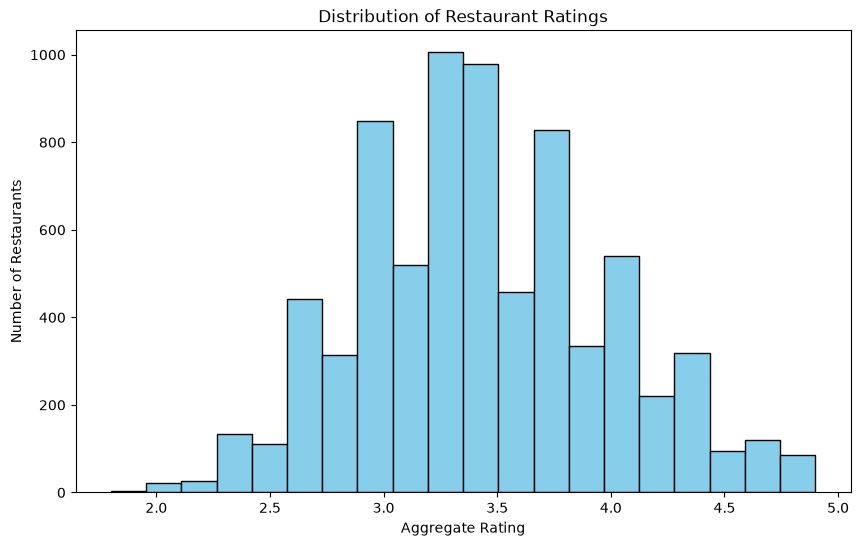

In [10]:
plt.figure(figsize=(10, 6))
plt.hist(rated_df["Aggregate rating"], bins=20, color='skyblue', edgecolor='black')
plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")
plt.show()

**Conclusion**
- The ratings are clustered in the middle around **3.2-3.5**, suggesting that ratings in this range is the most common for Zomato restaurants.
- There are few restaurants with really low ratings (2.0-2.4) or with high ratings (4.6-4.9).

## Restaurant - Price

In [11]:
rating_by_price = (
    rated_df.groupby("Price range")["Aggregate rating"].agg(["count", "mean", "median", "std"]).round(2)
)
rating_by_price

,count,mean,median,std
Price range,,,,
1,2744,3.24,3.2,0.44
2,2711,3.38,3.4,0.53
3,1373,3.78,3.8,0.54
4,575,3.89,3.9,0.52


<Figure size 1000x600 with 0 Axes>

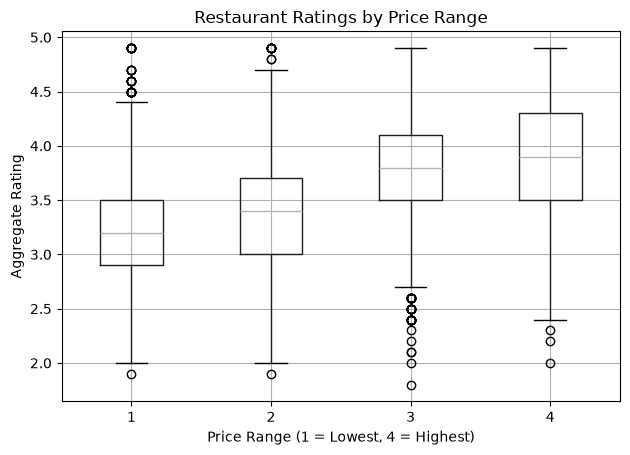

In [12]:
plt.figure(figsize=(10, 6))
rated_df.boxplot(
    column="Aggregate rating",
    by="Price range",
)
plt.title("Restaurant Ratings by Price Range")
plt.suptitle("")  # Suppress the default title to avoid overlap
plt.xlabel("Price Range (1 = Lowest, 4 = Highest)")
plt.ylabel("Aggregate Rating")
plt.tight_layout()
plt.show()

**Conclusion**
- The average rating is increased at every price range level, especially the distance between price range 1 and 4, the gap is **3.8 - 3.25 = 0.65** points on a 5-point scale, the increase is significant and worth looking into.
- However, the sample size of range 1 and range 4 vastly differed, range 1 has 2,744 to 575 of range 4. This could very much affect how the ratings are distributed.

## Indian Restaurant
This data set is heavily concentrated in India with over 90% of restaurants situated there. suppose some expensive restaurants are more common in certain countries or cities where ratings also tend to be higher. We should try looking into how zomato price - rating is distributed within India.

In [19]:
india_rated = rated_df[rated_df["Country Code"] == 1].copy()

india_rating_by_price = (
    india_rated.groupby("Price range")["Aggregate rating"].agg(["count", "mean", "median", "std"]).round(2)
)
india_rating_by_price

,count,mean,median,std
Price range,,,,
1,2596,3.20,3.1,0.41
2,2462,3.31,3.3,0.50
3,1078,3.68,3.7,0.52
4,377,3.73,3.8,0.49


<Figure size 1000x600 with 0 Axes>

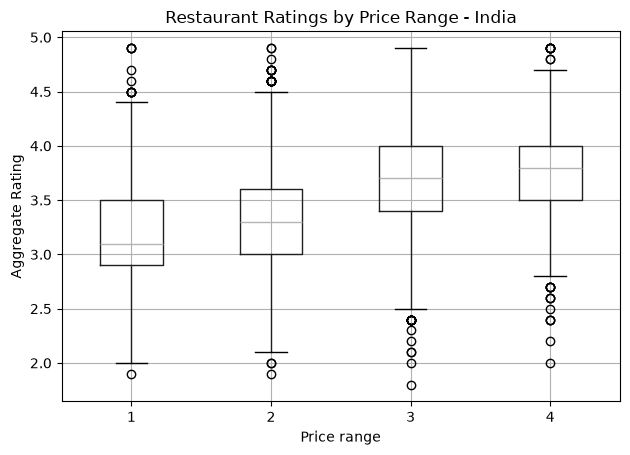

In [21]:
plt.figure(figsize=(10, 6))
india_rated.boxplot(
    column="Aggregate rating",
    by="Price range",
)

plt.title("Restaurant Ratings by Price Range - India")
plt.suptitle("")
plt.xlabel("Price range")
plt.ylabel("Aggregate Rating")
plt.tight_layout()
plt.show()

**Conclusion**
- Since India represented a large chunk of the data set and the distribution for restaurant ratings by price range in India is similar to the total data set as a whole, we can say strongly that pricing alone doesn't explain the difference in ratings

## Services - Ratings

In [25]:
service_cols = [
    "Has Table booking",
    "Has Online delivery"
]

for col in service_cols:
    print(df[col].value_counts())
    print(
        (df[col].value_counts(normalize=True) * 100).round(2).astype(str) + "%"
    )

Has Table booking
No     8393
Yes    1158
Name: count, dtype: int64
Has Table booking
No     87.88%
Yes    12.12%
Name: proportion, dtype: str
Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64
Has Online delivery
No     74.34%
Yes    25.66%
Name: proportion, dtype: str


In [34]:
service_combinations = (
    df.groupby(service_cols).size().reset_index(name="Restaurant Count").sort_values("Restaurant Count", ascending=False)
)

service_combinations["Share (%)"] = (
    (service_combinations["Restaurant Count"] / len(df) * 100).round(2)
)
service_combinations

,Has Table booking,Has Online delivery,Restaurant Count,Share (%)
0,No,No,6377,66.77
1,No,Yes,2016,21.11
2,Yes,No,723,7.57
3,Yes,Yes,435,4.55


In [35]:
rated_service_combinations = (
    rated_df.groupby(service_cols)["Aggregate rating"].agg(["count", "mean", "median", "std"]).round(2)
)

rated_service_combinations

count  mean  median   std
Has Table booking Has Online delivery                           
No                No                    4370  3.45     3.4  0.56
                  Yes                   1922  3.33     3.4  0.53
Yes               No                     678  3.57     3.6  0.54
                  Yes                    433  3.61     3.7  0.53

**Conclusion**
- Most restaurants, more than 66%, within the data set have neither online delivery and table booking. In contrast, restaurants that have both is only 435, only barely 4.5%.
- For restaurants that have online delivery alone, they tends to have lower ratings, on average between don't have online delivery and have online delivery, there is a **-0.12** difference. This could be due to the is delivering now as if the only additional service that those restaurants provide is unavailable, it could lead to dissatisfaction. Nevertheless, this requires additional analysis between online delivery and is delivering now.
- On the other hand, restaurants with table booking have higher rating on average 3.57 to 3.45 without online delivery, and for restaurants with both, they have even higher average rating, 3.61 to 3.33 among restaurants with online delivery. 

Text(0.5, 1.0, 'Mean Restaurant Ratings by Service Combination')

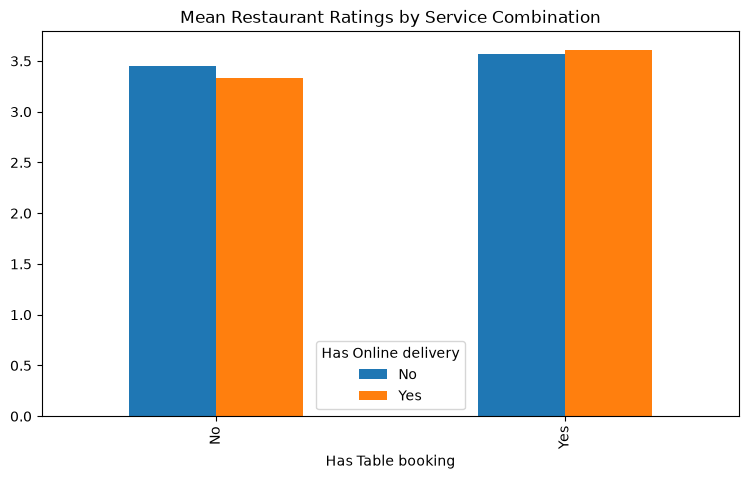

In [37]:
service_means = (
    rated_df.groupby(["Has Table booking", "Has Online delivery"])["Aggregate rating"].mean().unstack()
)

ax = service_means.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title("Mean Restaurant Ratings by Service Combination")

In [40]:
service_by_price = (
    rated_df.groupby([
        "Price range",
        "Has Table booking",
        "Has Online delivery"
    ])["Aggregate rating"].agg(["count", "mean", "median"]).round(2)
)

service_by_price

count  mean  median
Price range Has Table booking Has Online delivery                     
1           No                No                    2096  3.23    3.10
                              Yes                    647  3.26    3.30
            Yes               Yes                      1  3.70    3.70
2           No                No                    1367  3.43    3.40
                              Yes                   1124  3.32    3.40
            Yes               No                      99  3.23    3.20
                              Yes                    121  3.48    3.50
3           No                No                     611  3.97    4.00
                              Yes                    138  3.68    3.80
            Yes               No                     353  3.60    3.60
                              Yes                    271  3.63    3.70
4           No                No                     296  4.05    4.10
                              Yes                     13  4.08    4.10
            Yes               No                     226  3.67    3.70
                              Yes                     40  3.88    3.85

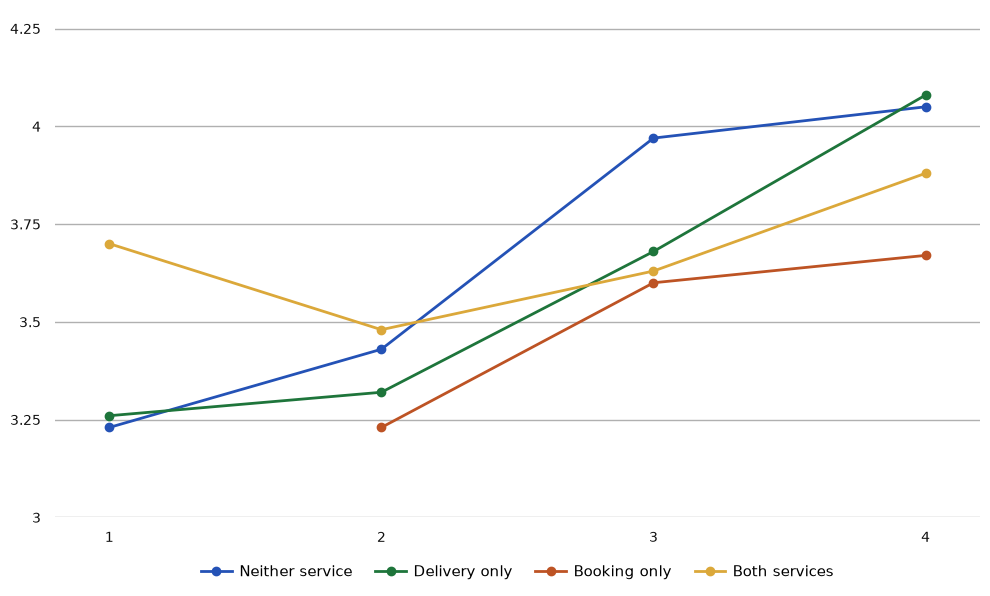

In [62]:
service_price_data_plot = service_by_price["mean"].unstack(level=["Has Table booking", "Has Online delivery"])
mapping = {
    ("No", "No"): "Neither service",
    ("No", "Yes"): "Delivery only",
    ("Yes", "No"): "Booking only",
    ("Yes", "Yes"): "Both services",
}
service_price_data_plot.columns = service_price_data_plot.columns.map(mapping)

fig, ax = plt.subplots(figsize=(10, 6))

colors = {
    'Neither service': '#2452B6',
    'Delivery only': '#1E753B',
    'Booking only': '#BD5324',
    'Both services': '#DBA83A'
}

for column in colors:
    if column in service_price_data_plot.columns:
        series = service_price_data_plot[column].dropna()
        ax.plot(series.index, series.values, color=colors[column], marker="o", linewidth=2, label=column)

ax.set_xlim(0.8, 4.2)
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(["1", "2", "3", "4"], color="#0F0F0F", fontsize=10)

ax.set_ylim(3, 4.3)
ax.set_yticks([3, 3.25, 3.5, 3.75, 4, 4.25])
ax.set_yticklabels(["3", "3.25", "3.5", "3.75", "4", "4.25"], color="#0F0F0F", fontsize=10)

ax.grid(axis="y", linestyle="-", linewidth=1)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis="both", which="both", length=0, pad=10)

ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False, fontsize=11, handletextpad=0.5, columnspacing=1.5)

plt.tight_layout()
plt.show()

**Conclusion**
- For different price ranges, online delivery actually affect ratings differently.
+ At price range 1: delivery-only restaurants average 3.26 to 3.23 for neither service
+ At price range 2: 3.32 to 3.43
+ At price range 3: 3.68 to 3.97
+ At price range 4: 4.08 to 4.05
- For table booking, its affect on raing also differs at various price ranges, for example, at price range 3 restaurants without online delivery, those with table booking average 3.6 to 3.97 without booking.
- Furthermore, both services in price range 1 and delivery only in price range 4 both have too small a sample size to represent those groups.

### Is delivering now

In [63]:
pd.crosstab(
    df["Has Online delivery"],
    df["Is delivering now"],
    margins=True
)

Is delivering now,No,Yes,All
Has Online delivery,,,
No,7100,0,7100
Yes,2417,34,2451
All,9517,34,9551


In [64]:
delivery_status_ratings = (
    rated_df.groupby(
        ["Has Online delivery", "Is delivering now"]
    )["Aggregate rating"].agg(["count", "mean", "median"]).round(2)
)

delivery_status_ratings

count  mean  median
Has Online delivery Is delivering now                     
No                  No                  5048  3.47     3.4
Yes                 No                  2322  3.38     3.4
                    Yes                   33  3.25     3.4

**Conclusion**
- This findings indicate that the hypothesis I made for **online delivery to have lower ratings due to not providing the service even when they have it is inaccurate**. In contrast, restaurants having delivery and even still providing the service have lower ratings of 3.25 compared to 3.47 for restaurants that don't have the service.